In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   --- ------------------------------------ 4.7/48.9 MB 23.7 MB/s eta 0:00:02
   ------- -------------------------------- 9.4/48.9 MB 23.5 MB/s eta 0:00:02
   ---------- ----------------------------- 13.4/48.9 MB 22.1 MB/s eta 0:00:02
   ------------- -------------------------- 17.0/48.9 MB 21.1 MB/s eta 0:00:02
   ----------------- ---------------------- 21.5/48.9 MB 20.9 MB/s eta 0:00:02
   -------------------- ------------------- 24.6/48.9 MB 20.0 MB/s eta 0:00:02
   ---------------------- ----------------- 28.0/48.9 MB 19.5 MB/s eta 0:00:02
   ------------------------- -------------- 31.7/48.9 MB 19.4 MB/s eta 0:00:01
   ----------------------------- ---------- 35.7/48.9 MB 19.2 MB/s eta 0:00:01
   -------------------------------- ------- 40.4/48.9 MB 19.6 MB/s eta 0:00:01
   ------------------------------------ --- 44.6/48.9 MB 19.6 MB/s eta 0:00:01
   ---------------------------------------  48.2/48.9 MB 19.3 M

In [ ]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load the dataset
dataset = load_breast_cancer(as_frame=True)

# Separate the input data and target
X = dataset.data
y = dataset.target

# Display the first five rows
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nTarget classes:", dataset.target_names)
print("\nFirst five target values:")
print(y.head())

Number of samples: 569
Number of features: 30

Target classes: ['malignant' 'benign']

First five target values:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int32


Before training any ML model, we need to understand the data we're giving it. We'll answer three questions:
1. Are there any missing values?
2. How many benign and malignant cases are there?
3. Is the dataset imbalanced?

1. Check the dataset

In [7]:
X.shape

(569, 30)

In [8]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [9]:
X.isnull().sum().sum()

0

In [10]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


2. Count benign and malignant cases

In [13]:
class_counts = y.value_counts().sort_index()
class_counts

target
0    212
1    357
Name: count, dtype: int64

In [14]:
print(class_counts.rename(index=dict(enumerate(dataset.target_names))))

target
malignant    212
benign       357
Name: count, dtype: int64


In [17]:
# Calculate percentages
print("Class percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Class percentages:
target
1    62.74
0    37.26
Name: proportion, dtype: float64


3. Visualize the class distribution

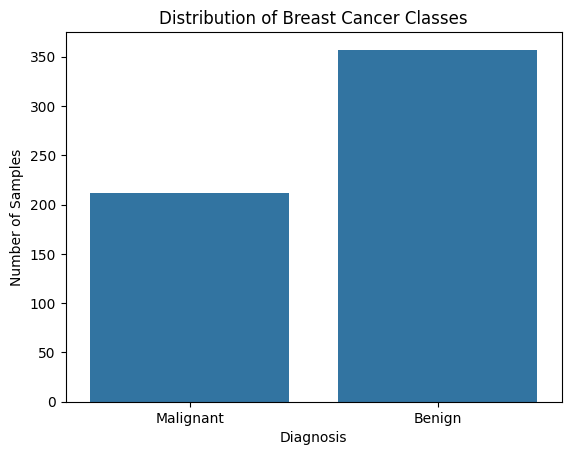

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x=y.map({0: "Malignant", 1: "Benign"}))

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.show()

In [ ]:
Check duplicate records

In [19]:
print("Duplicate rows:", X.duplicated().sum())

Duplicate rows: 0


Compare features by diagnosis

In [20]:
exploration_df = X.copy()

exploration_df["diagnosis"] = y.map({
    0: "Malignant",
    1: "Benign"
})

exploration_df.groupby("diagnosis").mean().T.head(10)

diagnosis,Benign,Malignant
mean radius,12.146524,17.462830
mean texture,17.914762,21.604906
mean perimeter,78.075406,115.365377
mean area,462.790196,978.376415
mean smoothness,0.092478,0.102898
mean compactness,0.080085,0.145188
mean concavity,0.046058,0.160775
mean concave points,0.025717,0.087990
mean symmetry,0.174186,0.192909
mean fractal dimension,0.062867,0.062680
